In [5]:
import sys, os, glob
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')
!pip -q install pretty_midi

UTENTE = 'martinopaoloni-ux'
BRANCH = 'main'

!rm -rf /content/MozartAI
!git clone -b {BRANCH} https://github.com/{UTENTE}/MozartAI.git /content/MozartAI
percorsi = glob.glob('/content/MozartAI/**/pipeline.py', recursive=True)
assert percorsi, "pipeline.py non trovato nel branch: hai fatto commit e push?"
sys.path.insert(0, os.path.dirname(percorsi[0]))

from pipeline import foto_a_audio, misura_tempi, carica_modello_una_volta
from IPython.display import Audio, display
print("Import ok")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Cloning into '/content/MozartAI'...
remote: Enumerating objects: 154, done.
remote: Counting objects: 100% (154/154), done.
remote: Compressing objects: 100% (147/147), done.
remote: Total 154 (delta 69), reused 8 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (154/154), 11.19 MiB | 11.32 MiB/s, done.
Resolving deltas: 100% (69/69), done.
Import ok


In [6]:
import time, torch
MODELLO = '/content/drive/MyDrive/MozartAI/checkpoints_v2/best.pt'
print("GPU:", torch.cuda.is_available(), "(deve essere False)")

t0 = time.perf_counter(); carica_modello_una_volta(MODELLO); print(f"Prima volta : {time.perf_counter() - t0:.2f} s")
t0 = time.perf_counter(); carica_modello_una_volta(MODELLO); print(f"Seconda volta: {time.perf_counter() - t0:.4f} s")

GPU: False (deve essere False)
Prima volta : 2.10 s
Seconda volta: 0.0001 s


5 foto
ok: True | Ho riconosciuto 1 rigo/righi e 2 note. Alcuni simboli sono stati saltati (2 avvisi).
Rigo 1: clef-F3 keySignature-AbM timeSignature-6/4 gracenote-Eb3_quarter note-Bb3_half gracenote-Eb3_quarter barline gracenote-Eb3_quarter tie gracenote-Eb3_quarter gracenote-Eb3_quarter note-D3_half.
{'caricamento_modello': 0.0, 'preprocessing': 1.21, 'modello': 1.07, 'midi': 0.01, 'audio': 0.02, 'totale': 2.38}


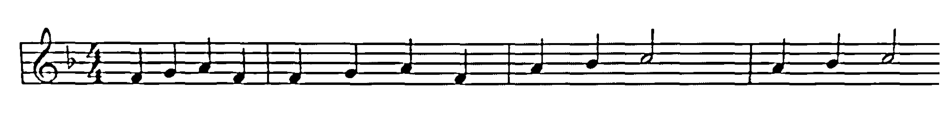

In [9]:
CARTELLA = '/content/drive/MyDrive/MozartAI/Foto Prova'
FOTO = sorted(os.path.join(CARTELLA, f) for f in os.listdir(CARTELLA) if f.lower().endswith(('.jpg', '.jpeg', '.png')))
print(len(FOTO), "foto")

r = foto_a_audio(FOTO[0], MODELLO)
print("ok:", r.ok, "|", r.messaggio)
print(r.testo_simboli())
print({k: round(v, 2) for k, v in r.tempi.items()})

for rigo in r.righi:
    plt.figure(figsize=(12, 2)); plt.imshow(rigo, cmap='gray'); plt.axis('off'); plt.show()
if r.ok:
    fs, onda = r.audio
    display(Audio(onda, rate=fs))

In [13]:
from PIL import Image
casi = {
    'foto bianca (nessun pentagramma)': np.full((900, 1200, 3), 235, np.uint8),
    'file che non esiste': '/content/non_esiste.jpg',
    'dati che non sono un\'immagine': b'ciao',
    'immagine minuscola': np.zeros((10, 10, 3), np.uint8),
    'nessuna foto': None,
}
for nome, x in casi.items():
    r = foto_a_audio(x, MODELLO)
    print(f"{nome:35s} ok={r.ok} | {r.messaggio[:100]}")

# anche una foto come immagine PIL o come array (come la manda Gradio)
r = foto_a_audio(Image.open(FOTO[0]), MODELLO); print("PIL ok:", r.ok)

foto bianca (nessun pentagramma)    ok=False | Non ho trovato nessun pentagramma nella foto. Prova con più luce, avvicinandoti allo spartito e tene
file che non esiste                 ok=False | Non riesco a leggere la foto: controlla che sia un'immagine valida (JPG o PNG) e non troppo piccola.
dati che non sono un'immagine       ok=False | Non riesco a leggere la foto: controlla che sia un'immagine valida (JPG o PNG) e non troppo piccola.
immagine minuscola                  ok=False | Non riesco a leggere la foto: controlla che sia un'immagine valida (JPG o PNG) e non troppo piccola.
nessuna foto                        ok=False | Non riesco a leggere la foto: controlla che sia un'immagine valida (JPG o PNG) e non troppo piccola.
PIL ok: True


In [14]:
!nproc
t = misura_tempi(FOTO[0], MODELLO, ripetizioni=3)
for fase, sec in t.items():
    print(f"{fase:15s} {sec:6.2f} s")

2
preprocessing     0.11 s
modello           0.25 s
midi              0.00 s
audio             0.01 s
totale            0.37 s


In [15]:
for f in FOTO:
    r = foto_a_audio(f, MODELLO)
    print(f"{os.path.basename(f):28s} {r.tempi['totale']:5.1f} s | righi: {len(r.righi)} | {r.messaggio[:50]}")

IMG_3276.jpeg                  0.4 s | righi: 1 | Ho riconosciuto 1 rigo/righi e 2 note. Alcuni simb
IMG_3277.jpeg                  1.1 s | righi: 1 | Ho riconosciuto 1 rigo/righi e 4 note. Alcuni simb
IMG_3278.jpeg                  0.9 s | righi: 1 | Ho riconosciuto 1 rigo/righi e 6 note. Alcuni simb
IMG_3279.jpeg                  1.1 s | righi: 2 | Ho riconosciuto 2 rigo/righi e 17 note. Alcuni sim
IMG_3280.jpeg                  1.7 s | righi: 2 | Ho riconosciuto 2 rigo/righi e 19 note. Alcuni sim
